# 05 - Optimisation des hyperparamètres : k-NN et SVM (sections 2.2 et 2.4)

Dans ce notebook, l'objectif est d'entraîner et d'optimiser deux modèles fondés sur des distances : le k-NN et le SVM.

**Méthode commune à tout le groupe :** validation croisée stratifiée à 5 plis (`StratifiedKFold`), métrique F1, recherche sur le train uniquement. Le jeu de test n'est utilisé qu'au notebook 04.

In [2]:
import sys
from pathlib import Path

# Remonte jusqu'à la racine du projet (le dossier qui contient src/), quel que soit le dossier de lancement
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

from src.load_data import load_wine_data, make_binary_target, split_data
from src.preprocess import clean_data
from src.models import (
    KNN_GRID, SVM_DISTRIBUTIONS, knn, svm, load_selected_features, save_model,
)

from src.tuning import run_grid_search, run_random_search
from src.evaluate import train_vs_cv_scores

## 1. Données et variables retenues

In [3]:
df = make_binary_target(clean_data(load_wine_data()))
X_train, X_test, y_train, y_test = split_data(df)
features = load_selected_features()

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Variables retenues (notebook 02) :", features)

Lignes supprimées (doublons ou NA) : 1177
Train : (4256, 12) | Test : (1064, 12)
Variables retenues (notebook 02) : ['volatile acidity', 'residual sugar', 'density', 'alcohol']


## 2. k-NN (k plus proches voisins)

### 2.1 Modèle par défaut (k = 5, vote uniforme, distance euclidienne)

In [4]:
knn_base = pd.DataFrame({
    "4 variables": train_vs_cv_scores(knn(features), X_train, y_train),
    "12 variables": train_vs_cv_scores(knn(None), X_train, y_train),
}).T
knn_base.round(3)

,train,validation,validation_std,ecart
4 variables,0.585,0.393,0.023,0.192
12 variables,0.629,0.467,0.023,0.163


### 2.2 Grid Search sur k, la pondération, la distance et le jeu de variables


In [5]:
knn_grid = {**KNN_GRID, "prep__select__columns": [features, None]}
knn_search = run_grid_search(knn(features), knn_grid, X_train, y_train)

print("Meilleurs hyperparamètres :", knn_search.best_params_)
print("F1 moyen en validation croisée :", round(knn_search.best_score_, 3))

Meilleurs hyperparamètres : {'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'distance', 'prep__select__columns': None}
F1 moyen en validation croisée : 0.496


In [6]:
knn_cv = pd.DataFrame(knn_search.cv_results_)
knn_cv["variables"] = knn_cv["param_prep__select__columns"].apply(
    lambda c: "4 variables" if isinstance(c, list) else "12 variables"
)
knn_cv["k"] = knn_cv["param_model__n_neighbors"].astype(int)

cols = ["k", "param_model__weights", "param_model__p", "variables",
        "mean_train_score", "mean_test_score", "std_test_score"]
knn_cv.sort_values("mean_test_score", ascending=False)[cols].head(10).round(3)

,k,param_model__weights,param_model__p,variables,mean_train_score,mean_test_score,std_test_score
19,5,distance,1,12 variables,1.000,0.496,0.035
11,3,distance,1,12 variables,1.000,0.491,0.031
15,3,distance,2,12 variables,1.000,0.490,0.013
27,7,distance,1,12 variables,1.000,0.483,0.023
23,5,distance,2,12 variables,1.000,0.482,0.029
13,3,uniform,2,12 variables,0.715,0.480,0.015
17,5,uniform,1,12 variables,0.629,0.473,0.033
9,3,uniform,1,12 variables,0.715,0.473,0.033
35,9,distance,1,12 variables,1.000,0.472,0.018
3,1,distance,1,12 variables,1.000,0.471,0.019


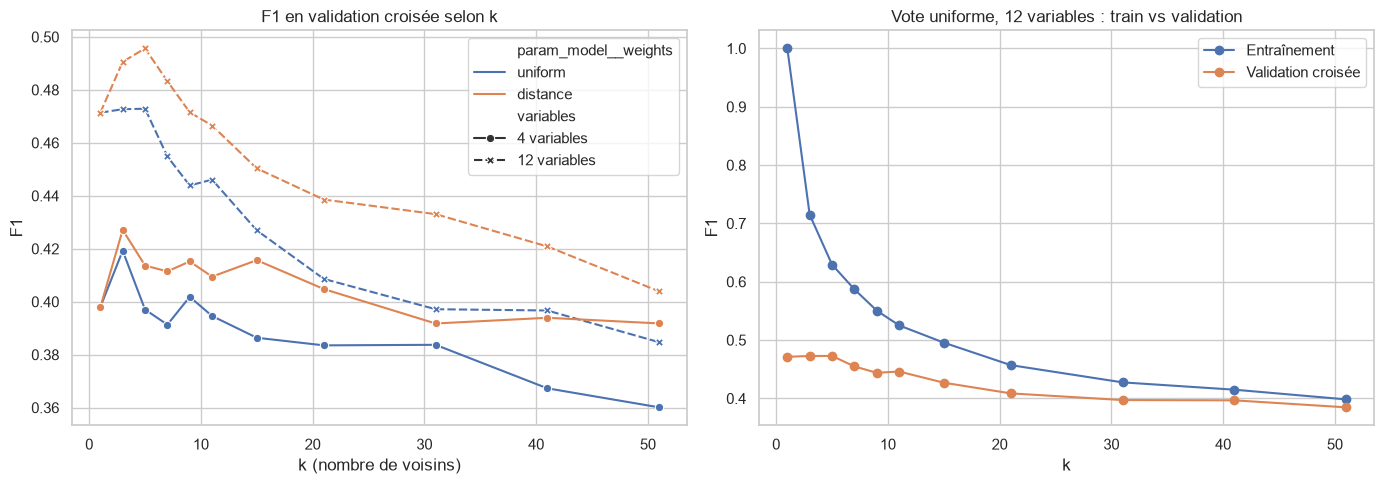

In [7]:
sub = knn_cv[knn_cv["param_model__p"] == 1]   # distance de Manhattan, la meilleure

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(data=sub, x="k", y="mean_test_score", hue="param_model__weights",
             style="variables", markers=True, ax=axes[0])
axes[0].set(title="F1 en validation croisée selon k", xlabel="k (nombre de voisins)", ylabel="F1")

uni = sub[(sub["param_model__weights"] == "uniform") & (sub["variables"] == "12 variables")]
axes[1].plot(uni["k"], uni["mean_train_score"], "o-", label="Entraînement")
axes[1].plot(uni["k"], uni["mean_test_score"], "o-", label="Validation croisée")
axes[1].set(title="Vote uniforme, 12 variables : train vs validation", xlabel="k", ylabel="F1")
axes[1].legend()

plt.tight_layout()
plt.show()

### 2.3 Ajustement du seuil de décision

In [8]:
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from src.models import make_pipeline
from src.tuning import CV

knn_tuned = TunedThresholdClassifierCV(
    make_pipeline(KNeighborsClassifier(p=1), None),   # Manhattan, 12 variables
    scoring="f1", cv=CV,
)
knn_tuned_grid = {
    "estimator__model__n_neighbors": [5, 9, 15, 21, 31, 41, 51, 71, 101],
    "estimator__model__weights": ["uniform", "distance"],
}
knn_t_search = run_grid_search(knn_tuned, knn_tuned_grid, X_train, y_train)

print("Meilleurs hyperparamètres :", knn_t_search.best_params_)
print("Seuil optimal :", round(knn_t_search.best_estimator_.best_threshold_, 3))
print("F1 moyen en validation croisée :", round(knn_t_search.best_score_, 3))

Meilleurs hyperparamètres : {'estimator__model__n_neighbors': 9, 'estimator__model__weights': 'distance'}
Seuil optimal : 0.323
F1 moyen en validation croisée : 0.553


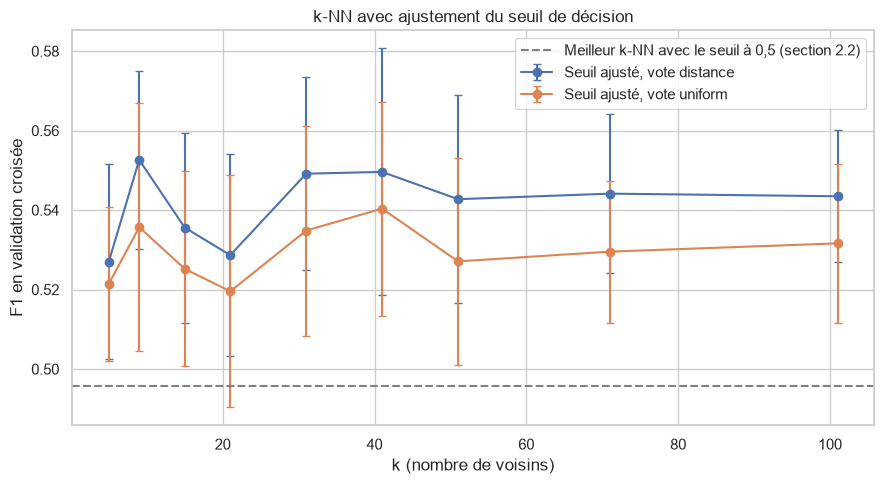

,k,param_estimator__model__weights,mean_train_score,mean_test_score,std_test_score
3,9,distance,1.000,0.553,0.022
11,41,distance,1.000,0.550,0.031
9,31,distance,1.000,0.549,0.024
15,71,distance,1.000,0.544,0.020
17,101,distance,1.000,0.543,0.017
13,51,distance,1.000,0.543,0.026
10,41,uniform,0.559,0.540,0.027
2,9,uniform,0.618,0.536,0.031


In [9]:
knn_t_cv = pd.DataFrame(knn_t_search.cv_results_)
knn_t_cv["k"] = knn_t_cv["param_estimator__model__n_neighbors"].astype(int)

plt.figure(figsize=(9, 5))
for w, g in knn_t_cv.groupby("param_estimator__model__weights"):
    plt.errorbar(g["k"], g["mean_test_score"], yerr=g["std_test_score"],
                 fmt="o-", capsize=3, label=f"Seuil ajusté, vote {w}")
plt.axhline(knn_search.best_score_, ls="--", color="grey",
            label="Meilleur k-NN avec le seuil à 0,5 (section 2.2)")
plt.xlabel("k (nombre de voisins)")
plt.ylabel("F1 en validation croisée")
plt.title("k-NN avec ajustement du seuil de décision")
plt.legend()
plt.tight_layout()
plt.show()

cols = ["k", "param_estimator__model__weights", "mean_train_score", "mean_test_score", "std_test_score"]
knn_t_cv.sort_values("mean_test_score", ascending=False)[cols].head(8).round(3)

In [10]:
from sklearn.base import clone

# Modèle retenu : k = 41, vote uniforme (règle de simplicité, voir l'analyse ci-dessous)
knn_final = clone(knn_tuned).set_params(
    estimator__model__n_neighbors=41,
    estimator__model__weights="uniform",
).fit(X_train, y_train)

print("Seuil optimal :", round(knn_final.best_threshold_, 3))
pd.Series(train_vs_cv_scores(knn_final, X_train, y_train)).round(3)

Seuil optimal : 0.293


train             0.559
validation        0.540
validation_std    0.027
ecart             0.019
dtype: float64

In [11]:
save_model(knn_final, "knn")

## 3. SVM (machine à vecteurs de support)

### 3.1 Modèles par défaut (C = 1, gamma = "scale", class_weight = "balanced")

In [12]:
rows = {}
for kernel in ["linear", "rbf"]:
    for label, cols in [("4 variables", features), ("12 variables", None)]:
        model = svm(cols).set_params(model__kernel=kernel)
        rows[(kernel, label)] = train_vs_cv_scores(model, X_train, y_train)

# Même SVM RBF, sans compenser le déséquilibre, pour mesurer l'effet de class_weight
rows[("rbf sans class_weight", "12 variables")] = train_vs_cv_scores(
    svm(None).set_params(model__class_weight=None), X_train, y_train
)

svm_base = pd.DataFrame(rows).T
svm_base.round(3)

train  validation  validation_std  ecart
linear                4 variables   0.524       0.523           0.014  0.001
                      12 variables  0.534       0.531           0.020  0.003
rbf                   4 variables   0.525       0.516           0.013  0.008
                      12 variables  0.584       0.542           0.017  0.043
rbf sans class_weight 12 variables  0.435       0.389           0.027  0.046

### 3.2 Random Search sur le noyau, C et gamma

In [13]:
svm_search = run_random_search(svm(None), SVM_DISTRIBUTIONS, X_train, y_train, n_iter=60)

print("Meilleurs hyperparamètres :", svm_search.best_params_)
print("F1 moyen en validation croisée :", round(svm_search.best_score_, 3))

Meilleurs hyperparamètres : {'model__C': np.float64(0.37306104754535907), 'model__gamma': np.float64(0.03490225247838249), 'model__kernel': 'rbf'}
F1 moyen en validation croisée : 0.541


Tirages par noyau et meilleur F1 obtenu :
                     count    max
param_model__kernel              
linear                  32  0.532
rbf                     28  0.541


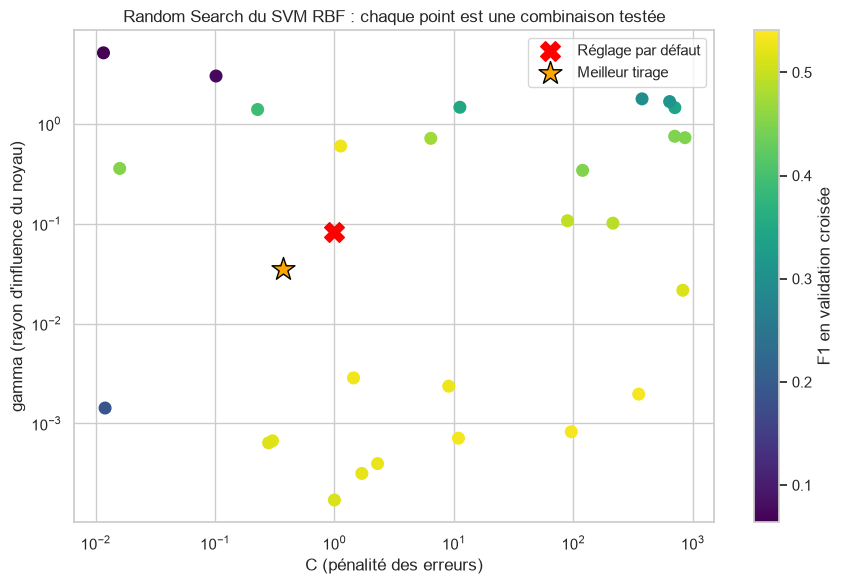

,param_model__kernel,C,gamma,mean_train_score,mean_test_score,std_test_score
51,rbf,0.3731,0.0349,0.5490,0.5406,0.0102
0,rbf,96.0981,0.0008,0.5435,0.5338,0.0116
21,rbf,352.0481,0.0020,0.5556,0.5335,0.0148
15,rbf,10.9075,0.0007,0.5328,0.5324,0.0251
12,linear,0.0230,NaN,0.5316,0.5319,0.0254
39,linear,0.2716,NaN,0.5338,0.5316,0.0219
19,linear,0.5762,NaN,0.5334,0.5315,0.0221
36,linear,0.1493,NaN,0.5336,0.5314,0.0224


In [14]:
svm_cv = pd.DataFrame(svm_search.cv_results_)
svm_cv["C"] = svm_cv["param_model__C"].astype(float)
svm_cv["gamma"] = pd.to_numeric(svm_cv["param_model__gamma"], errors="coerce")  # vide pour le noyau linéaire

print("Tirages par noyau et meilleur F1 obtenu :")
print(svm_cv.groupby("param_model__kernel")["mean_test_score"].agg(["count", "max"]).round(3))

# Valeur de gamma utilisée par défaut ("scale") : 1 / (nombre de variables × variance des données)
X_prep = svm(None).named_steps["prep"].fit_transform(X_train)
gamma_scale = 1 / (X_prep.shape[1] * X_prep.values.var())

rbf = svm_cv[svm_cv["param_model__kernel"] == "rbf"]
best = svm_search.best_params_

plt.figure(figsize=(9, 6))
sc = plt.scatter(rbf["C"], rbf["gamma"], c=rbf["mean_test_score"], cmap="viridis", s=70)
plt.colorbar(sc, label="F1 en validation croisée")
plt.scatter(1, gamma_scale, marker="X", s=200, color="red", label="Réglage par défaut")
if best["model__kernel"] == "rbf":
    plt.scatter(best["model__C"], best["model__gamma"], marker="*", s=300,
                color="orange", edgecolor="black", label="Meilleur tirage")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("C (pénalité des erreurs)")
plt.ylabel("gamma (rayon d'influence du noyau)")
plt.title("Random Search du SVM RBF : chaque point est une combinaison testée")
plt.legend()
plt.tight_layout()
plt.show()

cols = ["param_model__kernel", "C", "gamma", "mean_train_score", "mean_test_score", "std_test_score"]
svm_cv.sort_values("mean_test_score", ascending=False)[cols].head(8).round(4)

In [15]:
save_model(svm_search.best_estimator_, "svm")

## 4. Grid Search ou Random Search : comparaison des deux méthodes



In [16]:
import time

grid_svm = {
    "model__kernel": ["rbf"],
    "model__C": np.logspace(-2, 3, 8),       # 8 valeurs de 0,01 à 1 000, régulièrement espacées en log
    "model__gamma": np.logspace(-4, 1, 8),   # 8 valeurs de 0,0001 à 10
}
dist_svm = SVM_DISTRIBUTIONS[0]              # mêmes bornes, tirage log-uniforme (noyau RBF)

start = time.perf_counter()
grid_res = run_grid_search(svm(None), grid_svm, X_train, y_train)
grid_time = time.perf_counter() - start

start = time.perf_counter()
rand_res = run_random_search(svm(None), dist_svm, X_train, y_train, n_iter=16)
rand_time = time.perf_counter() - start

comparison_search = pd.DataFrame({
    "Grid Search (8 × 8)": {"combinaisons testées": 64, "meilleur F1": grid_res.best_score_,
                            "temps (s)": grid_time, **grid_res.best_params_},
    "Random Search (16 tirages)": {"combinaisons testées": 16, "meilleur F1": rand_res.best_score_,
                                   "temps (s)": rand_time, **rand_res.best_params_},
}).T
comparison_search

,combinaisons testées,meilleur F1,temps (s),model__C,model__gamma,model__kernel
Grid Search (8 × 8),64,0.548567,25.71002,0.26827,0.372759,rbf
Random Search (16 tirages),16,0.539608,6.176617,0.332056,0.042052,rbf


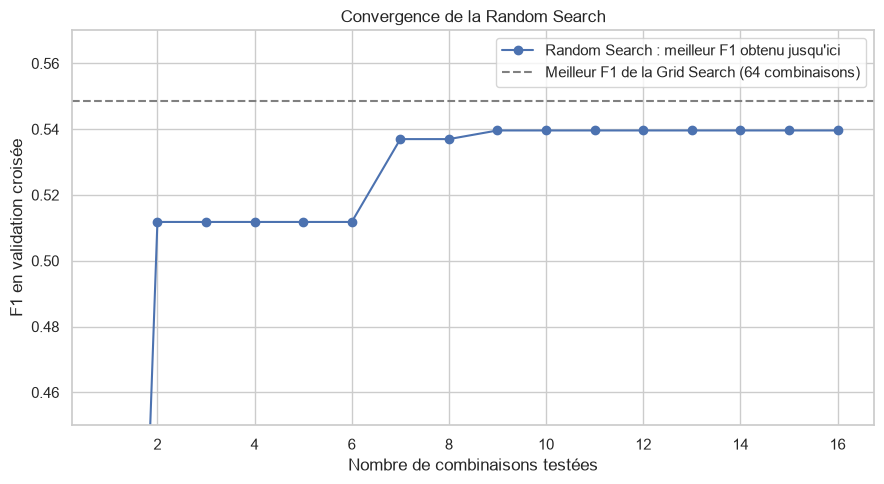

In [17]:
best_so_far = pd.DataFrame(rand_res.cv_results_)["mean_test_score"].cummax()

plt.figure(figsize=(9, 5))
plt.plot(range(1, 17), best_so_far, "o-", label="Random Search : meilleur F1 obtenu jusqu'ici")
plt.axhline(grid_res.best_score_, ls="--", color="grey", label="Meilleur F1 de la Grid Search (64 combinaisons)")
plt.xlabel("Nombre de combinaisons testées")
plt.ylabel("F1 en validation croisée")
plt.title("Convergence de la Random Search")
plt.ylim(0.45, 0.57)
plt.legend()
plt.tight_layout()
plt.show()